# Data analytics for TFLN experiment

Loading packages

In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

HEATMAP_DIR = 'Results/heatmaps'
os.makedirs(HEATMAP_DIR, exist_ok=True)

Data import statements

In [12]:
fine_scans = [
    {'label': '0.25 nC (fine)', 'path': 'Data_raw/July31_/finescaneQ0p25nC_wh5_4.npz'},
    {'label': '0.5 nC (fine)',  'path': 'Data_raw/July31_/finescaneQ0p5nC_wh5_1.npz'},
    {'label': '1 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ1nC_wh5_6.npz'},
    {'label': '4 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ4nC_wh4_5.npz'},
    {'label': '5 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ5nC_wh4_3.npz'},
    {'label': '7 nC (fine)',    'path': 'Data_raw/July31_/finescaneQ7nC_wh4_2.npz'},
    {'label': '10 nC (fine)',   'path': 'Data_raw/July31_/finescaneQ10nC_wh4_0.npz'},
]

In [13]:
# ── Loader and baseline stripper ─────────────────────────────────────────────

from scipy.ndimage import uniform_filter1d

RF_Hz      = 81.25e6
mV         = 1e3
T_LASER_NS = 1e9 / RF_Hz   # ≈ 12.31 ns — one laser period

# ── Signal window definition ─────────────────────────────────────────────────
SIGNAL_START_NS = 45.
SIGNAL_END_NS   = 75.
FLANK_END_NS    = 100.

# ── Processing parameters ─────────────────────────────────────────────────────
PROBE_HALF_WIN = 25

# FFT super-Gaussian low-pass filter.
#   FFT_SIGMA_GHZ : roll-off centre.  0 = disabled.
#   FFT_ORDER     : controls sharpness.  1 = standard Gaussian (gradual).
#                   Higher N → flatter passband, steeper cut.
#
#   Current settings (σ=0.35, N=6):
#     0.10 GHz → <0.01% attenuation   (signal fully preserved)
#     0.20 GHz → <0.07% attenuation   (signal fully preserved)
#     0.35 GHz → 39%   attenuation    (-3 dB point)
#     0.50 GHz → ~100% attenuation    (noise removed)
FFT_SIGMA_GHZ = 0.35
FFT_ORDER     = 3


def _period_fill_lookup(t_ns, signal_start, signal_end, flank_end):
    dt_ns    = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)
    T_samp   = T_LASER_NS / dt_ns
    i_sig0   = int(round(signal_start / dt_ns))
    i_sig1   = int(round(signal_end   / dt_ns))
    i_fl_end = int(round(flank_end    / dt_ns))
    idx   = np.arange(i_sig0, i_sig1)
    n_l   = np.ceil((idx + 1 - i_sig0) / T_samp).astype(int)
    n_r   = np.ceil((i_sig1 - idx)     / T_samp).astype(int)
    src_l = np.round(idx - n_l * T_samp).astype(int)
    src_r = np.round(idx + n_r * T_samp).astype(int)
    return i_sig0, i_sig1, src_l, src_r


def fft_lowpass(residual, dt_ns, sigma_GHz, order=FFT_ORDER):
    """
    Super-Gaussian low-pass filter applied row-wise in the frequency domain.
      filter(f) = exp( -0.5 * (f/σ)^(2·order) )
    order=1 → standard Gaussian;  order>1 → flatter passband, sharper cut-off.
    """
    n     = residual.shape[1]
    freqs = np.fft.rfftfreq(n, d=dt_ns)               # GHz
    filt  = np.exp(-0.5 * (freqs / sigma_GHz) ** (2 * order))
    F     = np.fft.rfft(residual, axis=1)
    return np.fft.irfft(F * filt[np.newaxis, :], n=n, axis=1)


def compute_baseline(traces, t_ns):
    i_sig0, i_sig1, src_l, src_r = _period_fill_lookup(
        t_ns, SIGNAL_START_NS, SIGNAL_END_NS, FLANK_END_NS)
    baseline = traces.copy()
    baseline[:, i_sig0:i_sig1] = 0.5 * (traces[:, src_l] + traces[:, src_r])
    return baseline



def extract_signed_amplitude(residual, half_win=PROBE_HALF_WIN):
    col_var = residual.var(axis=0)
    t_probe = col_var.argmax()
    n_samp  = residual.shape[1]
    win     = slice(max(0, t_probe - half_win), min(n_samp, t_probe + half_win))
    return residual[:, win].mean(axis=1)


def load_and_strip(path, ch=None,ft_sigma=FFT_SIGMA_GHZ, fft_order=FFT_ORDER):
    d        = np.load(path)
    BPDwf    = d['BPDwf']
    t_ns     = 1e9 * d['x'][0, :]
    phase    = d['phase']
    delay_ps = (phase - phase[0]) / RF_Hz / 360 * 1e12
    dt_ns    = (t_ns[-1] - t_ns[0]) / (len(t_ns) - 1)

    nchan = BPDwf.shape[1]
    if nchan == 10:
        traces = BPDwf.mean(axis=1)
    else:
        if ch is None:
            raise ValueError(f'ch must be specified for coarse scan (nchan={nchan})')
        traces = BPDwf[:, ch, :]

    baseline = compute_baseline(traces, t_ns)
    residual = traces - baseline

    if FFT_SIGMA_GHZ > 0:
        residual = fft_lowpass(residual, dt_ns, FFT_SIGMA_GHZ, order=fft_order)

    signed_amplitude = extract_signed_amplitude(residual)
    amplitude        = np.abs(signed_amplitude)

    return {'delay_ps': delay_ps, 'residual': residual,
            'signed_amplitude': signed_amplitude,
            'amplitude': amplitude,
            't_ns': t_ns, 'traces': traces}


# ── Load everything ───────────────────────────────────────────────────────────
results_coarse, results_fine = [], []
print(f'Fine scans    fft_σ={FFT_SIGMA_GHZ} GHz  order={FFT_ORDER}]:')
for exp in fine_scans:
    r = load_and_strip(exp['path'])
    r['label'] = exp['label']
    results_fine.append(r)
    print(f"  {exp['label']:20s}  peak = {mV * r['amplitude'].max():.1f} mV")


Fine scans    fft_σ=0.35 GHz  order=3]:
  0.25 nC (fine)        peak = 12.4 mV
  0.5 nC (fine)         peak = 25.4 mV
  1 nC (fine)           peak = 45.1 mV
  4 nC (fine)           peak = 128.4 mV
  5 nC (fine)           peak = 167.4 mV
  7 nC (fine)           peak = 206.3 mV
  10 nC (fine)          peak = 242.3 mV


# Heatmaps
Heatmaps of the data for each set in the cell above. Baseline is stripped, and heatmaps saved

In [ ]:
# ── Figure 2: Heatmaps — combined and individual per scan ─────────────────────

HEATMAP_COLS = 4   # panels per row in the combined figure

def label_to_filename(label):
    """'0.25 nC (fine)' → 'fine_0p25nC'"""
    charge = label.split()[0].replace('.', 'p')
    kind   = 'fine' if 'fine' in label else 'coarse'
    return f'{kind}_{charge}nC'

def draw_heatmap(ax, r, title=None):
    extent = [r['t_ns'][0], r['t_ns'][-1],
              r['delay_ps'][0], r['delay_ps'][-1]]
    vmax = np.percentile(np.abs(mV * r['residual']), 98)
    im = ax.imshow(mV * r['residual'], aspect='auto', extent=extent,
                   origin='lower', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(title or r['label'], fontsize=9)
    ax.set_xlabel('time (ns)', fontsize=8)
    ax.set_ylabel('phase delay (ps)', fontsize=8)
    plt.colorbar(im, ax=ax, label='residual (mV)', shrink=0.8)

# ── Individual file per fine scan ─────────────────────────────────────────────
if True:
    for r in results_fine:
        fig, ax = plt.subplots(figsize=(7, 4))
        draw_heatmap(ax, r)
        plt.tight_layout()
        fname = f'{HEATMAP_DIR}/{label_to_filename(r["label"])}_heatmap.png'
        plt.savefig(fname, dpi=200, bbox_inches='tight')
        plt.show()
        print(f'Saved {fname}')

# ── Combined overview: wrap into rows of HEATMAP_COLS ─────────────────────────
all_scans = []
all_scans += results_fine

n_total = len(all_scans)
n_cols  = HEATMAP_COLS
n_rows  = int(np.ceil(n_total / n_cols))

fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(5 * n_cols, 5 * n_rows),
                         squeeze=False)

for idx, r in enumerate(all_scans):
    ax = axes[idx // n_cols, idx % n_cols]
    draw_heatmap(ax, r)

# Hide any unused panels in the last row
for idx in range(n_total, n_rows * n_cols):
    axes[idx // n_cols, idx % n_cols].set_visible(False)

plt.suptitle('Baseline-stripped BPD — heatmaps by charge', fontsize=12, y=1.01)
plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/charge_comparison_heatmaps.png', dpi=200, bbox_inches='tight')
plt.show()

# Balanced Photodiode Data View

Graphs of balanced photodiode data in time domain, raw signed voltage output and magnitude. Peak to peak voltages aren't reported here


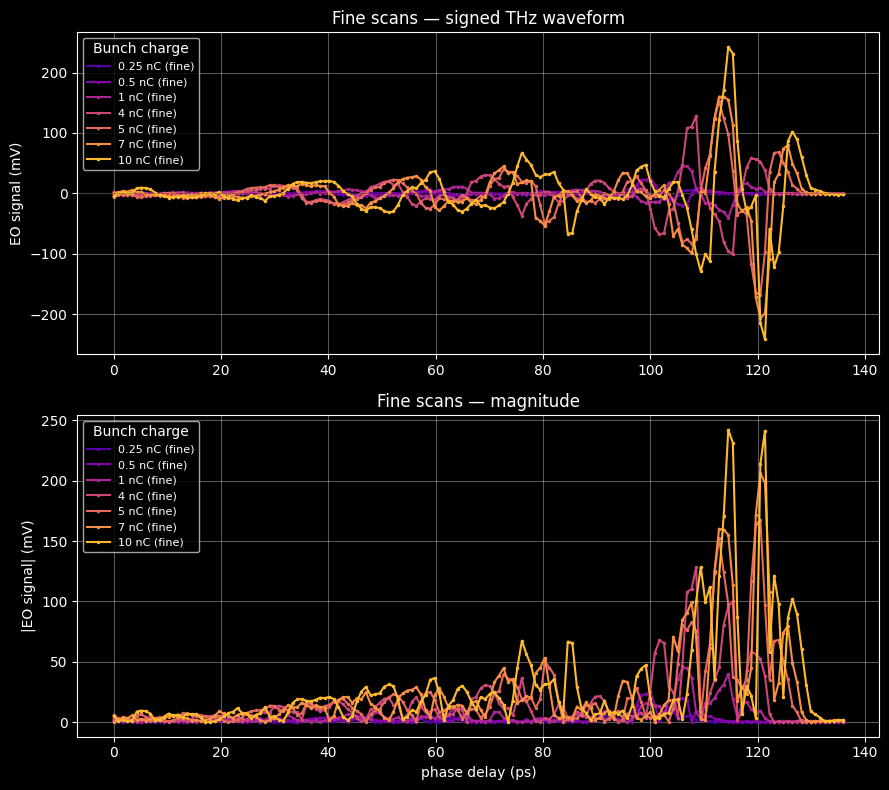

In [ ]:
n_rows = 1
fig, axes = plt.subplots(n_rows * 2, 1, figsize=(9, 4 * n_rows * 2), squeeze=False)
ax_idx = 0

def plot_group_signed(ax_signed, ax_mag, results, title):
    colors = cm.plasma(np.linspace(0.15, 0.85, len(results)))
    for r, col in zip(results, colors):
        dp  = r['delay_ps']
        sig = mV * r['signed_amplitude']
        ax_signed.plot(dp, sig, color=col, lw=1.5, marker='.', markersize=3, label=r['label'])
        ax_mag.plot(dp, np.abs(sig), color=col, lw=1.5, marker='.', markersize=3, label=r['label'])
    ax_signed.axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
    ax_signed.set_ylabel('EO signal (mV)')
    ax_signed.set_title(f'{title} — signed THz waveform')
    ax_signed.legend(title='Bunch charge', fontsize=8)
    ax_signed.grid(True, alpha=0.35)
    ax_mag.set_xlabel('phase delay (ps)')
    ax_mag.set_ylabel('|EO signal| (mV)')
    ax_mag.set_title(f'{title} — magnitude')
    ax_mag.legend(title='Bunch charge', fontsize=8)
    ax_mag.grid(True, alpha=0.35)


plot_group_signed(axes[ax_idx, 0], axes[ax_idx + 1, 0],
                   results_fine, 'Fine scans')

plt.tight_layout()
plt.savefig('charge_comparison_amplitude.png', dpi=200)
plt.show()

## Additional BPD data metrics
The integral of the BPD across the phase delay axis

In [ ]:
# ── Time integral of the BPD voltage across all charge tests ──────────────────
# For each fine scan, integrate the signed BPD voltage V(t) over the phase-delay
# axis (the THz time axis).  Units: V·ps  (= 1e-12 V·s).

import re

def charge_from_label(label):
    """'0.25 nC (fine)' → 0.25"""
    return float(re.match(r'([\d.]+)', label).group(1))

rows = []
for r in results_fine:
    t_ps  = r['delay_ps']
    v_sig = r['signed_amplitude']                  # V
    int_signed = np.trapezoid(v_sig,         t_ps) # V·ps
    int_abs    = np.trapezoid(np.abs(v_sig), t_ps) # V·ps
    rows.append({
        'label':      r['label'],
        'charge_nC':  charge_from_label(r['label']),
        'int_signed': int_signed,
        'int_abs':    int_abs,
    })

rows.sort(key=lambda x: x['charge_nC'])

# ── Tabular report ────────────────────────────────────────────────────────────
print(f'{"scan":<20s}  {"Q (nC)":>7s}  {"∫V dt signed (mV·ps)":>22s}  {"∫|V| dt (mV·ps)":>18s}')
print('-' * 74)
for row in rows:
    print(f"{row['label']:<20s}  {row['charge_nC']:>7.2f}  "
          f"{mV * row['int_signed']:>22.2f}  {mV * row['int_abs']:>18.2f}")

# ── Plot integral vs bunch charge ─────────────────────────────────────────────
charges   = np.array([r['charge_nC']  for r in rows])
int_signs = np.array([r['int_signed'] for r in rows]) * mV   # mV·ps
int_abss  = np.array([r['int_abs']    for r in rows]) * mV   # mV·ps

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(charges, int_signs, 'o-', color='C0', lw=1.5, markersize=6)
ax1.axhline(0, color='k', lw=0.6, ls='--', alpha=0.4)
ax1.set_xlabel('Bunch charge (nC)')
ax1.set_ylabel(r'$\int V_{\mathrm{BPD}}(t)\, dt$  (mV·ps)')
ax1.set_title('Signed time-integral of BPD voltage')
ax1.grid(True, alpha=0.35)

ax2.plot(charges, int_abss, 's-', color='C3', lw=1.5, markersize=6)
ax2.set_xlabel('Bunch charge (nC)')
ax2.set_ylabel(r'$\int |V_{\mathrm{BPD}}(t)|\, dt$  (mV·ps)')
ax2.set_title('Magnitude time-integral of BPD voltage')
ax2.grid(True, alpha=0.35)

plt.tight_layout()
plt.savefig(f'{HEATMAP_DIR}/bpd_time_integral_vs_charge.png', dpi=200, bbox_inches='tight')
plt.show()


## Log-Log Power Law Fits — BPD Metrics vs Charge

Fits $y = A \cdot Q^{\alpha}$ in log-log space for the three BPD voltage metrics:

- **P2P** — peak-to-peak within ±200 samples around the probe pulse
- **Magnitude** — peak $|$signed amplitude$|$ from the probe-window estimator
- **Integral** — $\int |V|\ d\tau$ over the full phase-delay scan

$\alpha = 1$ is the fully coherent (linear) limit; $\alpha < 1$ indicates saturation or coherence loss at high charge.